In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [16]:
file_path = '/Users/wangwenfei/Desktop/python_decal_fa25/project/dataset/horizons_results_earth.txt'

In [17]:
with open(file_path, 'r') as file:
    lines = file.readlines()

start_index = None
end_index = None
for i, line in enumerate(lines):
    if '$$SOE' in line:
        start_index = i + 1
    if '$$EOE' in line:
        end_index = i
        break
print(f"Data start: {start_index}, Data end: {end_index}")

data_lines = lines[start_index:end_index]
print(f"Data lines: {len(data_lines)}")
orbital_data = []

for i in range(0, len(data_lines), 5):
    if i + 4 >= len(data_lines):
        break
        
    date_line = data_lines[i].strip()
    ec_line = data_lines[i+1].strip()
    om_line = data_lines[i+2].strip()
    n_line = data_lines[i+3].strip()
    a_line = data_lines[i+4].strip()
    
    try:
        date_str = date_line.split('=')[1].split('TDB')[0].strip()
        
        ec = float(ec_line.split('EC=')[1].split()[0])
        a = float(a_line.split('A =')[1].split()[0])
        pr = float(a_line.split('PR=')[1].split()[0])
        ma = float(n_line.split('MA=')[1].split()[0])
        
        orbital_data.append({
            'date': date_str,
            'eccentricity': ec,
            'semi_major_axis_km': a,
            'orbital_period_sec': pr,
            'mean_anomaly_deg': ma
        })
            
    except Exception as e:
        continue

df_earth = pd.DataFrame(orbital_data)
print("success")
print(f"Total data points: {len(df_earth)}")
print("\nFirst 5 rows:")
print(df_earth.head())

Data start: 59, Data end: 974
Data lines: 915
success
Total data points: 183

First 5 rows:
                             date  eccentricity  semi_major_axis_km  \
0  A.D. 2020-Jan-01 00:00:00.0000      0.017121        1.496538e+08   
1  A.D. 2020-Jan-11 00:00:00.0000      0.015876        1.494593e+08   
2  A.D. 2020-Jan-21 00:00:00.0000      0.017395        1.496909e+08   
3  A.D. 2020-Jan-31 00:00:00.0000      0.016883        1.496472e+08   
4  A.D. 2020-Feb-10 00:00:00.0000      0.016095        1.494583e+08   

   orbital_period_sec  mean_anomaly_deg  
0        3.157585e+07        355.831294  
1        3.151432e+07          7.191893  
2        3.158758e+07         16.875663  
3        3.157375e+07         24.963209  
4        3.151401e+07         38.416482  


In [18]:
print("Current columns in df_earth:")
print(df_earth.columns.tolist())

df_earth['semi_major_axis_au'] = df_earth['semi_major_axis_km'] / 149597870.700
df_earth['orbital_period_year'] = df_earth['orbital_period_sec'] / (365.25 * 24 * 3600)

print("\nAfter unit conversion - new columns:")
print(df_earth.columns.tolist())
print(f"semi_major_axis_au sample: {df_earth['semi_major_axis_au'].head(3).tolist()}")
print(f"orbital_period_year sample: {df_earth['orbital_period_year'].head(3).tolist()}")

avg_eccentricity = df_earth['eccentricity'].mean()
avg_semi_major_axis_au = df_earth['semi_major_axis_au'].mean()  
avg_orbital_period_year = df_earth['orbital_period_year'].mean()

print("\nEarth Orbital Parameters:")
print(f"Eccentricity: {avg_eccentricity:.6f}")
print(f"Semi-major axis: {avg_semi_major_axis_au:.6f} AU")
print(f"Orbital period: {avg_orbital_period_year:.6f} years")
print(f"Orbital period: {avg_orbital_period_year * 365.25:.2f} days")

Current columns in df_earth:
['date', 'eccentricity', 'semi_major_axis_km', 'orbital_period_sec', 'mean_anomaly_deg']

After unit conversion - new columns:
['date', 'eccentricity', 'semi_major_axis_km', 'orbital_period_sec', 'mean_anomaly_deg', 'semi_major_axis_au', 'orbital_period_year']
semi_major_axis_au sample: [1.0003738366513, 0.9990738529614673, 1.0006216307000237]
orbital_period_year sample: [1.000578201951778, 0.9986284618226038, 1.0009499919780918]

Earth Orbital Parameters:
Eccentricity: 0.016710
Semi-major axis: 1.000002 AU
Orbital period: 1.000021 years
Orbital period: 365.26 days


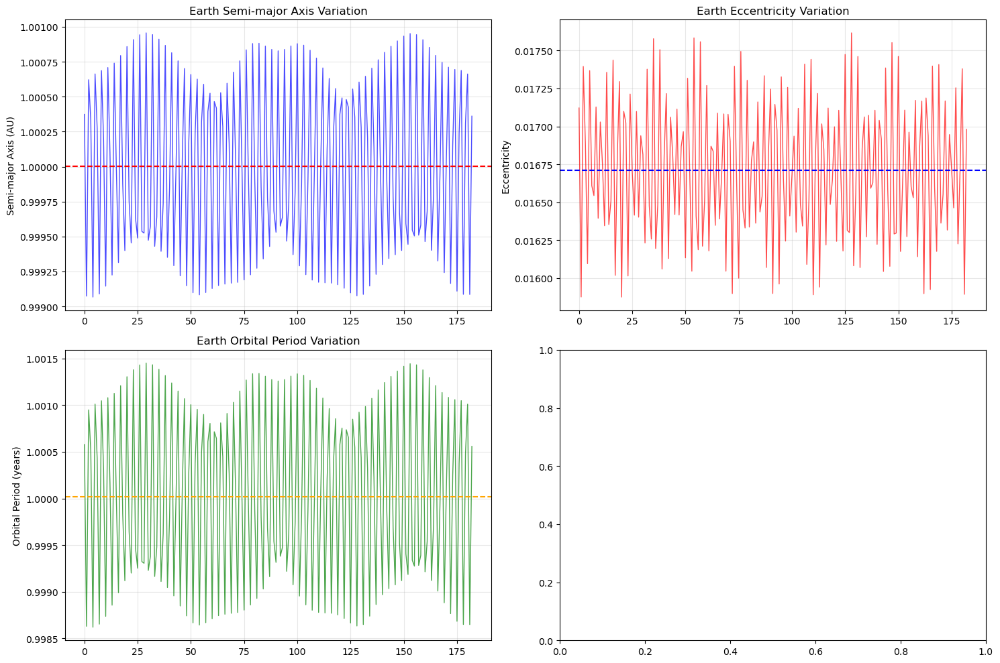

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes[0,0].plot(range(len(df_earth)), df_earth['semi_major_axis_au'], 'b-', alpha=0.7, linewidth=1)
axes[0,0].axhline(y=avg_semi_major_axis_au, color='r', linestyle='--')
axes[0,0].set_ylabel('Semi-major Axis (AU)')
axes[0,0].set_title('Earth Semi-major Axis Variation')
axes[0,0].grid(True, alpha=0.3)

axes[0,1].plot(range(len(df_earth)), df_earth['eccentricity'], 'r-', alpha=0.7, linewidth=1)
axes[0,1].axhline(y=avg_eccentricity, color='b', linestyle='--')
axes[0,1].set_ylabel('Eccentricity')
axes[0,1].set_title('Earth Eccentricity Variation')
axes[0,1].grid(True, alpha=0.3)

axes[1,0].plot(range(len(df_earth)), df_earth['orbital_period_year'], 'g-', alpha=0.7, linewidth=1)
axes[1,0].axhline(y=avg_orbital_period_year, color='orange', linestyle='--')
axes[1,0].set_ylabel('Orbital Period (years)')
axes[1,0].set_title('Earth Orbital Period Variation')
axes[1,0].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
earth_summary = {
    'planet': 'Earth',
    'semi_major_axis_au': avg_semi_major_axis_au,
    'orbital_period_year': avg_orbital_period_year,
    'eccentricity': avg_eccentricity
}

print("Earth Orbital Summary:")
for key, value in earth_summary.items():
    print(f"  {key}: {value}")

df_earth.to_csv('earth_orbital_data_processed.csv', index=False)

Earth Orbital Summary:
  planet: Earth
  semi_major_axis_au: 1.0000023030828609
  orbital_period_year: 1.0000209928321797
  eccentricity: 0.016709762138749605


In [21]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

earth_data = earth_for_simulation

simulation_years = 1
days_per_year = 365.25
frames_per_year = 100
num_frames = simulation_years * frames_per_year
days_per_frame = days_per_year / frames_per_year

print(f"Simulation: {simulation_years} years")
print(f"Total frames: {num_frames}")
print(f"Days per frame: {days_per_frame:.2f}")

fig, ax = plt.subplots(figsize=(10, 10))
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.set_title(f'Earth Orbital Simulation - {simulation_years} Years', fontsize=16)
ax.set_xlabel('X Position (AU)')
ax.set_ylabel('Y Position (AU)')

sun = ax.scatter([0], [0], color='yellow', s=300, label='Sun', zorder=5)
earth_dot = ax.scatter([], [], color='blue', s=80, label='Earth', zorder=5)
earth_trail, = ax.plot([], [], color='blue', alpha=0.5, linewidth=2, label='Orbit')

ax.legend(loc='upper right')

trail_x = []
trail_y = []

def init():
    earth_dot.set_offsets(np.zeros((1, 2)))
    earth_trail.set_data([], [])
    return earth_dot, earth_trail

def update(frame):
    current_days = frame * days_per_frame
    current_years = current_days / days_per_year
    
    angular_speed = 2 * np.pi / earth_data['period_year']
    angle = angular_speed * current_years
    
    x = earth_data['radius_au'] * np.cos(angle)
    y = earth_data['radius_au'] * np.sin(angle)
    
    earth_dot.set_offsets([[x, y]])
    
    trail_x.append(x)
    trail_y.append(y)
    earth_trail.set_data(trail_x, trail_y)
    
    years = int(current_years)
    days = int(current_days % days_per_year)
    ax.set_title(f'Earth: Year {years}, Day {days}', fontsize=14)
    
    return earth_dot, earth_trail

animation = FuncAnimation(fig, update, frames=num_frames,
                         init_func=init, blit=True, interval=30)

plt.close()
HTML(animation.to_jshtml())

Simulation: 1 years
Total frames: 100
Days per frame: 3.65


In [28]:
desktop_path = '/Users/wangwenfei/Desktop/python_decal_fa25/project/dataset/'
planet_files = {
    'Mercury': desktop_path + 'horizons_results_mercury.txt',
    'Venus': desktop_path + 'horizons_results_venus.txt', 
    'Earth': desktop_path + 'horizons_results_earth.txt',
    'Mars': desktop_path + 'horizons_results_mars.txt',
    'Jupiter': desktop_path + 'horizons_results_jupiter.txt',
    'Saturn': desktop_path + 'horizons_results_saturn.txt',
    'Uranus': desktop_path + 'horizons_results_uranus.txt',
    'Neptune': desktop_path + 'horizons_results_neptune.txt'
}

def parse_planet_data(file_path):
    with open(file_path, 'r') as file:
        lines = file.readlines()  
    start_index = None
    end_index = None
    for i, line in enumerate(lines):
        if '$$SOE' in line:
            start_index = i + 1
        if '$$EOE' in line:
            end_index = i
            break   
    if start_index is None or end_index is None:
        print(f"No data found in {file_path}")
        return None        
    data_lines = lines[start_index:end_index]
    orbital_data = []
    
    for i in range(0, len(data_lines), 5):
        if i + 4 >= len(data_lines):
            break            
        date_line = data_lines[i].strip()
        ec_line = data_lines[i+1].strip()
        om_line = data_lines[i+2].strip()
        n_line = data_lines[i+3].strip()
        a_line = data_lines[i+4].strip()
        
        try:
            date_str = date_line.split('=')[1].split('TDB')[0].strip()
            
            ec = float(ec_line.split('EC=')[1].split()[0])
            a = float(a_line.split('A =')[1].split()[0])
            pr = float(a_line.split('PR=')[1].split()[0])
            ma = float(n_line.split('MA=')[1].split()[0])
            
            orbital_data.append({
                'date': date_str,
                'eccentricity': ec,
                'semi_major_axis_km': a,
                'orbital_period_sec': pr,
                'mean_anomaly_deg': ma
            })
                
        except Exception as e:
            continue
    
    return pd.DataFrame(orbital_data)
solor_system_data = {}
planet_colors = {
    'Mercury': 'gray', 'Venus': 'yellow', 'Earth': 'blue', 
    'Mars': 'red', 'Jupiter': 'orange', 'Saturn': 'gold',
    'Uranus': 'lightblue', 'Neptune': 'blue'
}
planet_sizes = {
    'Mercury': 15, 'Venus': 20, 'Earth': 25, 'Mars': 18,
    'Jupiter': 50, 'Saturn': 45, 'Uranus': 35, 'Neptune': 35
}
print("Processing planetary data...")
for planet, filename in planet_files.items():
    try:
        df = parse_planet_data(filename)
        
        if df is not None and len(df) > 0:
            df['semi_major_axis_au'] = df['semi_major_axis_km'] / 149597870.700
            df['orbital_period_year'] = df['orbital_period_sec'] / (365.25 * 24 * 3600)
            
            avg_radius = df['semi_major_axis_au'].mean()
            avg_period = df['orbital_period_year'].mean()
            avg_eccentricity = df['eccentricity'].mean()
            
            solar_system_data[planet] = {
                'radius_au': avg_radius,
                'period_year': avg_period, 
                'eccentricity': avg_eccentricity,
                'color': planet_colors[planet],
                'size': planet_sizes[planet]
            }
            
            print(f"✓ {planet}")
        else:
            print(f"✗ {planet}")
    except FileNotFoundError:
        print(f"✗ {planet} file")

Processing planetary data...
✓ Mercury
✓ Venus
✓ Earth
✓ Mars
✓ Jupiter
✓ Saturn
✓ Uranus
✓ Neptune


In [30]:
def get_initial_positions(planet_name, df_planet):
    if len(df_planet) == 0:
        return 0.0
    
    first_row = df_planet.iloc[0]
    mean_anomaly_deg = first_row['mean_anomaly_deg']
    mean_anomaly_rad = np.radians(mean_anomaly_deg)
    
    return mean_anomaly_rad

initial_angles = {}

for planet in solar_system_data.keys():
    filename = planet_files[planet]
    df_planet = parse_planet_data(filename)
    initial_angle = get_initial_positions(planet, df_planet)
    initial_angles[planet] = initial_angle

In [40]:
from datetime import datetime, timedelta
simulation_years = 5
days_per_year = 365.25
frames_per_year = 20
num_frames = simulation_years * frames_per_year
days_per_frame = days_per_year / frames_per_year
start_date = datetime(2025, 1, 1)
max_radius = max(data['radius_au'] for data in solar_system_data.values())
plot_size = max_radius * 1.2
fig, ax = plt.subplots(figsize=(14, 14))
ax.set_xlim(-plot_size, plot_size)
ax.set_ylim(-plot_size, plot_size)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.set_title(f'Solar System Simulation - 2025 to 2030\nReal Initial Positions from NASA Horizons', fontsize=16)
ax.set_xlabel('X Position (AU)')
ax.set_ylabel('Y Position (AU)')
sun = ax.scatter([0], [0], color='yellow', s=150, label='Sun', zorder=10)
ax.scatter([0], [0], color='orange', s=50, zorder=10)
planet_dots = {}
planet_trails = {}
planet_labels = {}

for planet, data in solar_system_data.items():
    planet_dots[planet] = ax.scatter([], [], color=data['color'], s=data['size'], label=planet, zorder=5)
    planet_trails[planet], = ax.plot([], [], color=data['color'], alpha=0.3, linewidth=1.5)
    planet_labels[planet] = ax.text(0, 0, '', fontsize=9, color=data['color'], weight='bold')

ax.legend(loc='upper right')
time_text = ax.text(0.02, 0.98, '', transform=ax.transAxes, fontsize=12, 
                   verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
progress_text = ax.text(0.02, 0.02, '', transform=ax.transAxes, fontsize=10,
                       bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
trail_data = {planet: [[], []] for planet in solar_system_data}
def init():
    for planet in solar_system_data:
        initial_angle = initial_angles[planet]
        initial_x = solar_system_data[planet]['radius_au'] * np.cos(initial_angle)
        initial_y = solar_system_data[planet]['radius_au'] * np.sin(initial_angle)
        
        planet_dots[planet].set_offsets([[initial_x, initial_y]])
        planet_trails[planet].set_data([initial_x], [initial_y])
        
        label_offset = 0.8 if planet in ['Mercury', 'Venus', 'Earth', 'Mars'] else 1.2
        planet_labels[planet].set_position((initial_x * label_offset, initial_y * label_offset))
        planet_labels[planet].set_text(planet)
        trail_data[planet] = [[initial_x], [initial_y]]
    time_text.set_text(f'Date: {start_date.strftime("%Y-%m-%d")}\nElapsed: 0.00 years')
    progress_text.set_text('Progress: 0.0%')
    all_artists = list(planet_dots.values()) + list(planet_trails.values()) + list(planet_labels.values()) + [time_text, progress_text]
    return all_artists
def update(frame):
    current_days = frame * days_per_frame
    current_years = current_days / days_per_year
    current_date = start_date + timedelta(days=current_days)
    date_str = current_date.strftime('%Y-%m-%d')
    for planet, data in solar_system_data.items():
        angular_speed = 2 * np.pi / data['period_year']
        initial_angle = initial_angles[planet]
        angle = initial_angle + angular_speed * current_years
        x = data['radius_au'] * np.cos(angle)
        y = data['radius_au'] * np.sin(angle)       
        planet_dots[planet].set_offsets([[x, y]])        
        trail_data[planet][0].append(x)
        trail_data[planet][1].append(y) 
        if len(trail_data[planet][0]) > 300:
            trail_data[planet][0] = trail_data[planet][0][-300:]
            trail_data[planet][1] = trail_data[planet][1][-300:]  
        planet_trails[planet].set_data(trail_data[planet][0], trail_data[planet][1])
        label_offset = 0.8 if planet in ['Mercury', 'Venus', 'Earth', 'Mars'] else 1.2
        planet_labels[planet].set_position((x * label_offset, y * label_offset))
    progress = (frame + 1) / num_frames * 100
    time_text.set_text(f'Date: {date_str}\nElapsed: {current_years:.2f} years')
    progress_text.set_text(f'Progress: {progress:.1f}%')
    all_artists = list(planet_dots.values()) + list(planet_trails.values()) + list(planet_labels.values()) + [time_text, progress_text]
    return all_artists
animation = FuncAnimation(fig, update, frames=num_frames,
                         init_func=init, blit=True, interval=30)
plt.close()
HTML(animation.to_jshtml())

In [41]:
animation.save("solar_system.gif", writer="pillow")
from IPython.display import FileLink
FileLink("solar_system.gif")

/Users/wangwenfei/Desktop/python_decal_fa25/project/simulation/solar_system.gif